In [1]:
import os
import warnings
from math import pi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_curve, auc, f1_score
import shap

warnings.filterwarnings('ignore')

# Global styling
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'axes.linewidth': 1.5,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'xtick.direction': 'in',   
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'legend.fontsize': 10,
    'legend.frameon': False,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': True,   
    'axes.spines.right': True
})

def format_chem_mater(ax):
    ax.tick_params(direction='in', length=5, width=1.5, colors='k',
                   top=True, right=True, bottom=True, left=True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_visible(True)

L_SIGMA = r'$\log_{10}(\sigma_{RT})$ [S cm$^{-1}$]'

os.makedirs('final_figures', exist_ok=True)

# prepare datasets
df_features = pd.read_csv('SPE_dataset_v6_reduced.csv') 
df_targets = pd.read_csv('SPE_Dataset_ML_Ready_v2.csv') 

df = pd.merge(
    df_features, 
    df_targets[['source.doi', 'Tg_C', 'activation_energy_eV', 'Tensile_Strength_MPa', 
                'Current_Density_mA_cm2', 'Lifetime_Hours', 'Voltage_Limit_V', 'transference_number']], 
    on='source.doi', 
    how='inner'
)
df = df.dropna(subset=['log10_sigma'])

df = df.drop_duplicates(subset=['source.doi', 'temperature_C'], keep='first')

mask1 = (df['source.doi'] == '10.1021/acsaem.5c00186') & (df['temperature_C'] == 30)
df.loc[mask1, 'conductivity_S_per_cm'] = 0.0000241
df.loc[mask1, 'log10_sigma'] = np.log10(0.0000241)

mask2 = (df['source.doi'] == '10.1021/acs.nanolett.4c04611') & (df['temperature_C'] == 30)
df.loc[mask2, 'conductivity_S_per_cm'] = 0.0000026
df.loc[mask2, 'log10_sigma'] = np.log10(0.0000026)

df.loc[df['source.doi'] == '10.1021/acsaem.3c00061', 'Lifetime_Hours'] = 1000

df.loc[df['salt_F_to_C'] == 300000000, 'salt_F_to_C'] = 3.0
df.loc[df['salt_F_to_C'] > 100, 'salt_F_to_C'] = 3.0

litfsi_mask = np.isclose(df['salt_TPSA_mean'], 41.19, atol=0.5)
df.loc[litfsi_mask, 'salt_TPSA_mean'] = 87.4
df.loc[litfsi_mask, 'salt_ExactMolWt_mean'] = 286.96
df.loc[litfsi_mask, 'salt_MolWt_mean'] = 287.09

conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

arch_palette = {'SPE': '#3498db', 'GPE': '#e74c3c', 'CPE': '#2ecc71', 'Hybrid': '#9b59b6'}
arch_order = ['SPE', 'GPE', 'CPE', 'Hybrid']

print(f"Cleaned Dataset Shape: {df.shape}")

df.to_csv('dataset_final.csv')

Cleaned Dataset Shape: (652, 91)


In [2]:
df = pd.read_csv('dataset_final.csv')

In [3]:
# --- Panel 1a ---
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.histplot(df['log10_sigma'], bins=40, kde=True, color='#2c3e50', ax=ax, edgecolors='white')
ax.axvline(-4.0, color='#e74c3c', linestyle='--', linewidth=2, label=r'Target ($10^{-4}$)')
ax.set_xlabel(L_SIGMA)
ax.set_ylabel('Frequency')
ax.legend(loc='upper right')
format_chem_mater(ax)
plt.savefig('final_figures/1a.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 1b ---
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(data=df, x='source.year', y='log10_sigma', alpha=0.3, color='#95a5a6', edgecolor='w', ax=ax)
yearly_median = df.groupby('source.year')['log10_sigma'].median().reset_index()
yearly_median['smoothed_sigma'] = yearly_median['log10_sigma'].rolling(window=3, min_periods=1, center=True).mean()
sns.lineplot(data=yearly_median, x='source.year', y='smoothed_sigma', color='#2980b9', linewidth=3, ax=ax)
ax.set_xlabel('Publication Year')
ax.set_ylabel(L_SIGMA)
format_chem_mater(ax)
plt.savefig('final_figures/1b.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 1c ---
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(data=df, x='poly_TPSA_mean', y='log10_sigma', hue='Architecture', 
                palette=arch_palette, alpha=0.7, edgecolor='k', ax=ax)
ax.set_xlabel('Polymer Mean TPSA [Å²]')
ax.set_ylabel(L_SIGMA)
ax.legend(title='Architecture', loc='upper right', fontsize=9)
format_chem_mater(ax)
plt.savefig('final_figures/1c.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 1d ---
fig, ax = plt.subplots(figsize=(6.5, 5))
pca_cols = [c for c in df.columns if c.startswith('poly_') and df[c].dtype in ['float64', 'int64']]
df_pca = df.dropna(subset=pca_cols + ['Architecture'])
X_scaled = StandardScaler().fit_transform(df_pca[pca_cols])
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)
sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=df_pca['Architecture'], 
                palette=arch_palette, alpha=0.7, edgecolor='k', ax=ax)
ax.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.legend(title='Architecture', loc='upper right', fontsize=9)
format_chem_mater(ax)
plt.savefig('final_figures/1d.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved 1a, 1b, 1c, 1d to final_figures/")

Saved 1a, 1b, 1c, 1d to final_figures/


In [4]:
# --- Panel 2a ---
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.regplot(data=df, x='activation_energy_eV', y='log10_sigma', ax=ax,
            scatter_kws={'alpha':0.5, 'color':'#34495e'}, line_kws={'color':'#e74c3c'})
ax.set_xlabel('Activation Energy ($E_a$) [eV]', fontsize=12)
ax.set_ylabel(L_SIGMA, fontsize=12)
format_chem_mater(ax)
plt.savefig('final_figures/2a.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 2b ---
fig, ax = plt.subplots(figsize=(6.5, 5))
df_ratio = df[df['molar_ratio'] < 200].copy()
sns.scatterplot(data=df_ratio, x='molar_ratio', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=ax, s=60)
ax.set_xlabel('O:Li Molar Ratio', fontsize=12)
ax.set_ylabel(L_SIGMA, fontsize=12)
ax.legend(title='Electrolyte Type')
format_chem_mater(ax)
plt.savefig('final_figures/2b.png', dpi=300, bbox_inches='tight')
plt.close()

# Quantitative check for Reviewer 3 Q4 (Ether-only SPE subset at O:Li 15-20)
ether_spe = df_ratio[(df_ratio['poly_fr_ether_mean'] > 0) & (df_ratio['Architecture'] == 'SPE')]
sweet_spot_ether = ether_spe[(ether_spe['molar_ratio'] >= 15) & (ether_spe['molar_ratio'] <= 20)]
print(f"Ether-only SPEs total: n={len(ether_spe)} | In O:Li 15-20 sweet spot: n={len(sweet_spot_ether)}, median log10_sigma = {sweet_spot_ether['log10_sigma'].median():.2f}")

# --- Panel 2c ---
if os.path.exists('figures/Figure_6_DFT_Validation_complete.png'):
    dft_img = mpimg.imread('figures/Figure_6_DFT_Validation_complete.png')
    plt.imsave('final_figures/2c.png', dft_img)

# --- Panel 2d ---
fig, ax = plt.subplots(figsize=(6.5, 5))
df_vtf = df.dropna(subset=['Tg_C', 'temperature_C']).copy()
df_vtf['T_diff'] = df_vtf['temperature_C'] - df_vtf['Tg_C']
sns.scatterplot(data=df_vtf, x='T_diff', y='log10_sigma', hue='Architecture',
                hue_order=arch_order, palette=arch_palette, alpha=0.6, edgecolor='w', ax=ax, s=60)
ax.set_xlabel(r'Free Volume Proxy ($T_{test} - T_g$) [$^\circ$C]', fontsize=12)
ax.set_ylabel(L_SIGMA, fontsize=12)
ax.legend(title='Electrolyte Type')
format_chem_mater(ax)
plt.savefig('final_figures/2d.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved 2a, 2b, 2c, 2d to final_figures/")

Ether-only SPEs total: n=93 | In O:Li 15-20 sweet spot: n=23, median log10_sigma = -3.82
Saved 2a, 2b, 2c, 2d to final_figures/


In [5]:
# Preparation of ML data
df['High_Performance'] = (df['log10_sigma'] > -4.0).astype(int)
ml_cols_raw = [c for c in df.columns if (c.startswith('poly_') or c.startswith('salt_') or 
                                         c.startswith('solv_') or c.startswith('fill_') or 
                                         c == 'molar_ratio') 
                                         and df[c].dtype in ['float64', 'int64']]
df_ml = df.copy()
df_ml[ml_cols_raw] = df_ml[ml_cols_raw].fillna(0)
df_ml = df_ml.dropna(subset=['log10_sigma'])

corr_matrix = df_ml[ml_cols_raw].corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
collinear_features = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
ml_cols = [c for c in ml_cols_raw if c not in collinear_features]

X = df_ml[ml_cols]
y = df_ml['High_Performance']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1_scores = cross_val_score(rf, X, y, cv=cv, scoring='f1')
cv_auc_scores = cross_val_score(rf, X, y, cv=cv, scoring='roc_auc')

print(f"Train size: n={len(X_train)} | Test size: n={len(X_test)}")
print(f"5-Fold CV F1: {cv_f1_scores.mean():.3f} +/- {cv_f1_scores.std():.3f}")
print(f"5-Fold CV AUC: {cv_auc_scores.mean():.3f} +/- {cv_auc_scores.std():.3f}")

# --- Panel 3a ---
fig, ax = plt.subplots(figsize=(5.5, 5))
most_common_poly_wt = df['poly_ExactMolWt_mean'].mode()[0]
df_identical = df[df['poly_ExactMolWt_mean'] == most_common_poly_wt].copy()
df_identical['Recipe'] = 'Identical Host Matrix'
print(f"Panel 3a Identical Host Matrix (MolWt={most_common_poly_wt:.2f}) sample size: n={len(df_identical)}")

sns.violinplot(data=df_identical, x='Recipe', y='log10_sigma', palette='muted', inner='quartile', ax=ax)
ax.set_xlabel('Systems with Identical Polymer Backbone')
ax.set_ylabel(L_SIGMA)
format_chem_mater(ax)
plt.savefig('final_figures/3a.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 3b ---
y_prob = rf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color='#e74c3c', linewidth=2.5, label=f'RF Classifier (AUC = {roc_auc:.2f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
format_chem_mater(ax)
plt.savefig('final_figures/3b.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 3c ---
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_vals_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_vals_class1 = shap_values[:, :, 1]
else:
    shap_vals_class1 = shap_values

mean_abs_shap = np.abs(shap_vals_class1).mean(axis=0)
top_indices = np.argsort(mean_abs_shap)[::-1][:5]
top_features = X.columns[top_indices].str.replace('_mean', '', regex=False).tolist()
top_shap_vals = mean_abs_shap[top_indices]

fig, ax = plt.subplots(figsize=(5.5, 5))
sns.barplot(x=top_shap_vals, y=top_features, palette='viridis', ax=ax)
ax.set_xlabel('Mean |SHAP Value| (Impact on Conductivity)')
ax.set_title('Top 5 Predictive Descriptors', pad=15)
format_chem_mater(ax)
plt.savefig('final_figures/3c.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved 3a, 3b, 3c to final_figures/")

Train size: n=521 | Test size: n=131
5-Fold CV F1: 0.837 +/- 0.018
5-Fold CV AUC: 0.691 +/- 0.024
Panel 3a Identical Host Matrix (MolWt=164.10) sample size: n=192
Saved 3a, 3b, 3c to final_figures/


In [6]:
from sklearn.model_selection import GroupKFold

gkf = GroupKFold(n_splits=5)
# Group by exact polymer repeat-unit molecular weight 
groups = df_ml['poly_ExactMolWt_mean']

gkf_f1 = cross_val_score(rf, X, y, cv=gkf, groups=groups, scoring='f1')
gkf_auc = cross_val_score(rf, X, y, cv=gkf, groups=groups, scoring='roc_auc')

print(f"GroupKFold F1 : {gkf_f1.mean():.3f} (+/- {gkf_f1.std():.3f})")
print(f"GroupKFold AUC: {gkf_auc.mean():.3f} (+/- {gkf_auc.std():.3f})")

GroupKFold F1 : 0.875 (+/- 0.041)
GroupKFold AUC: 0.727 (+/- 0.041)


=== Holdout Test Set Metrics (n = 131) ===
True High-Performance (TP): 91 (Precision = 0.80, Recall = 0.89)
True Low-Performance  (TN): 6
False Positives       (FP): 23
False Negatives       (FN): 11
Test F1-Score: 0.843 | Test ROC-AUC: 0.70


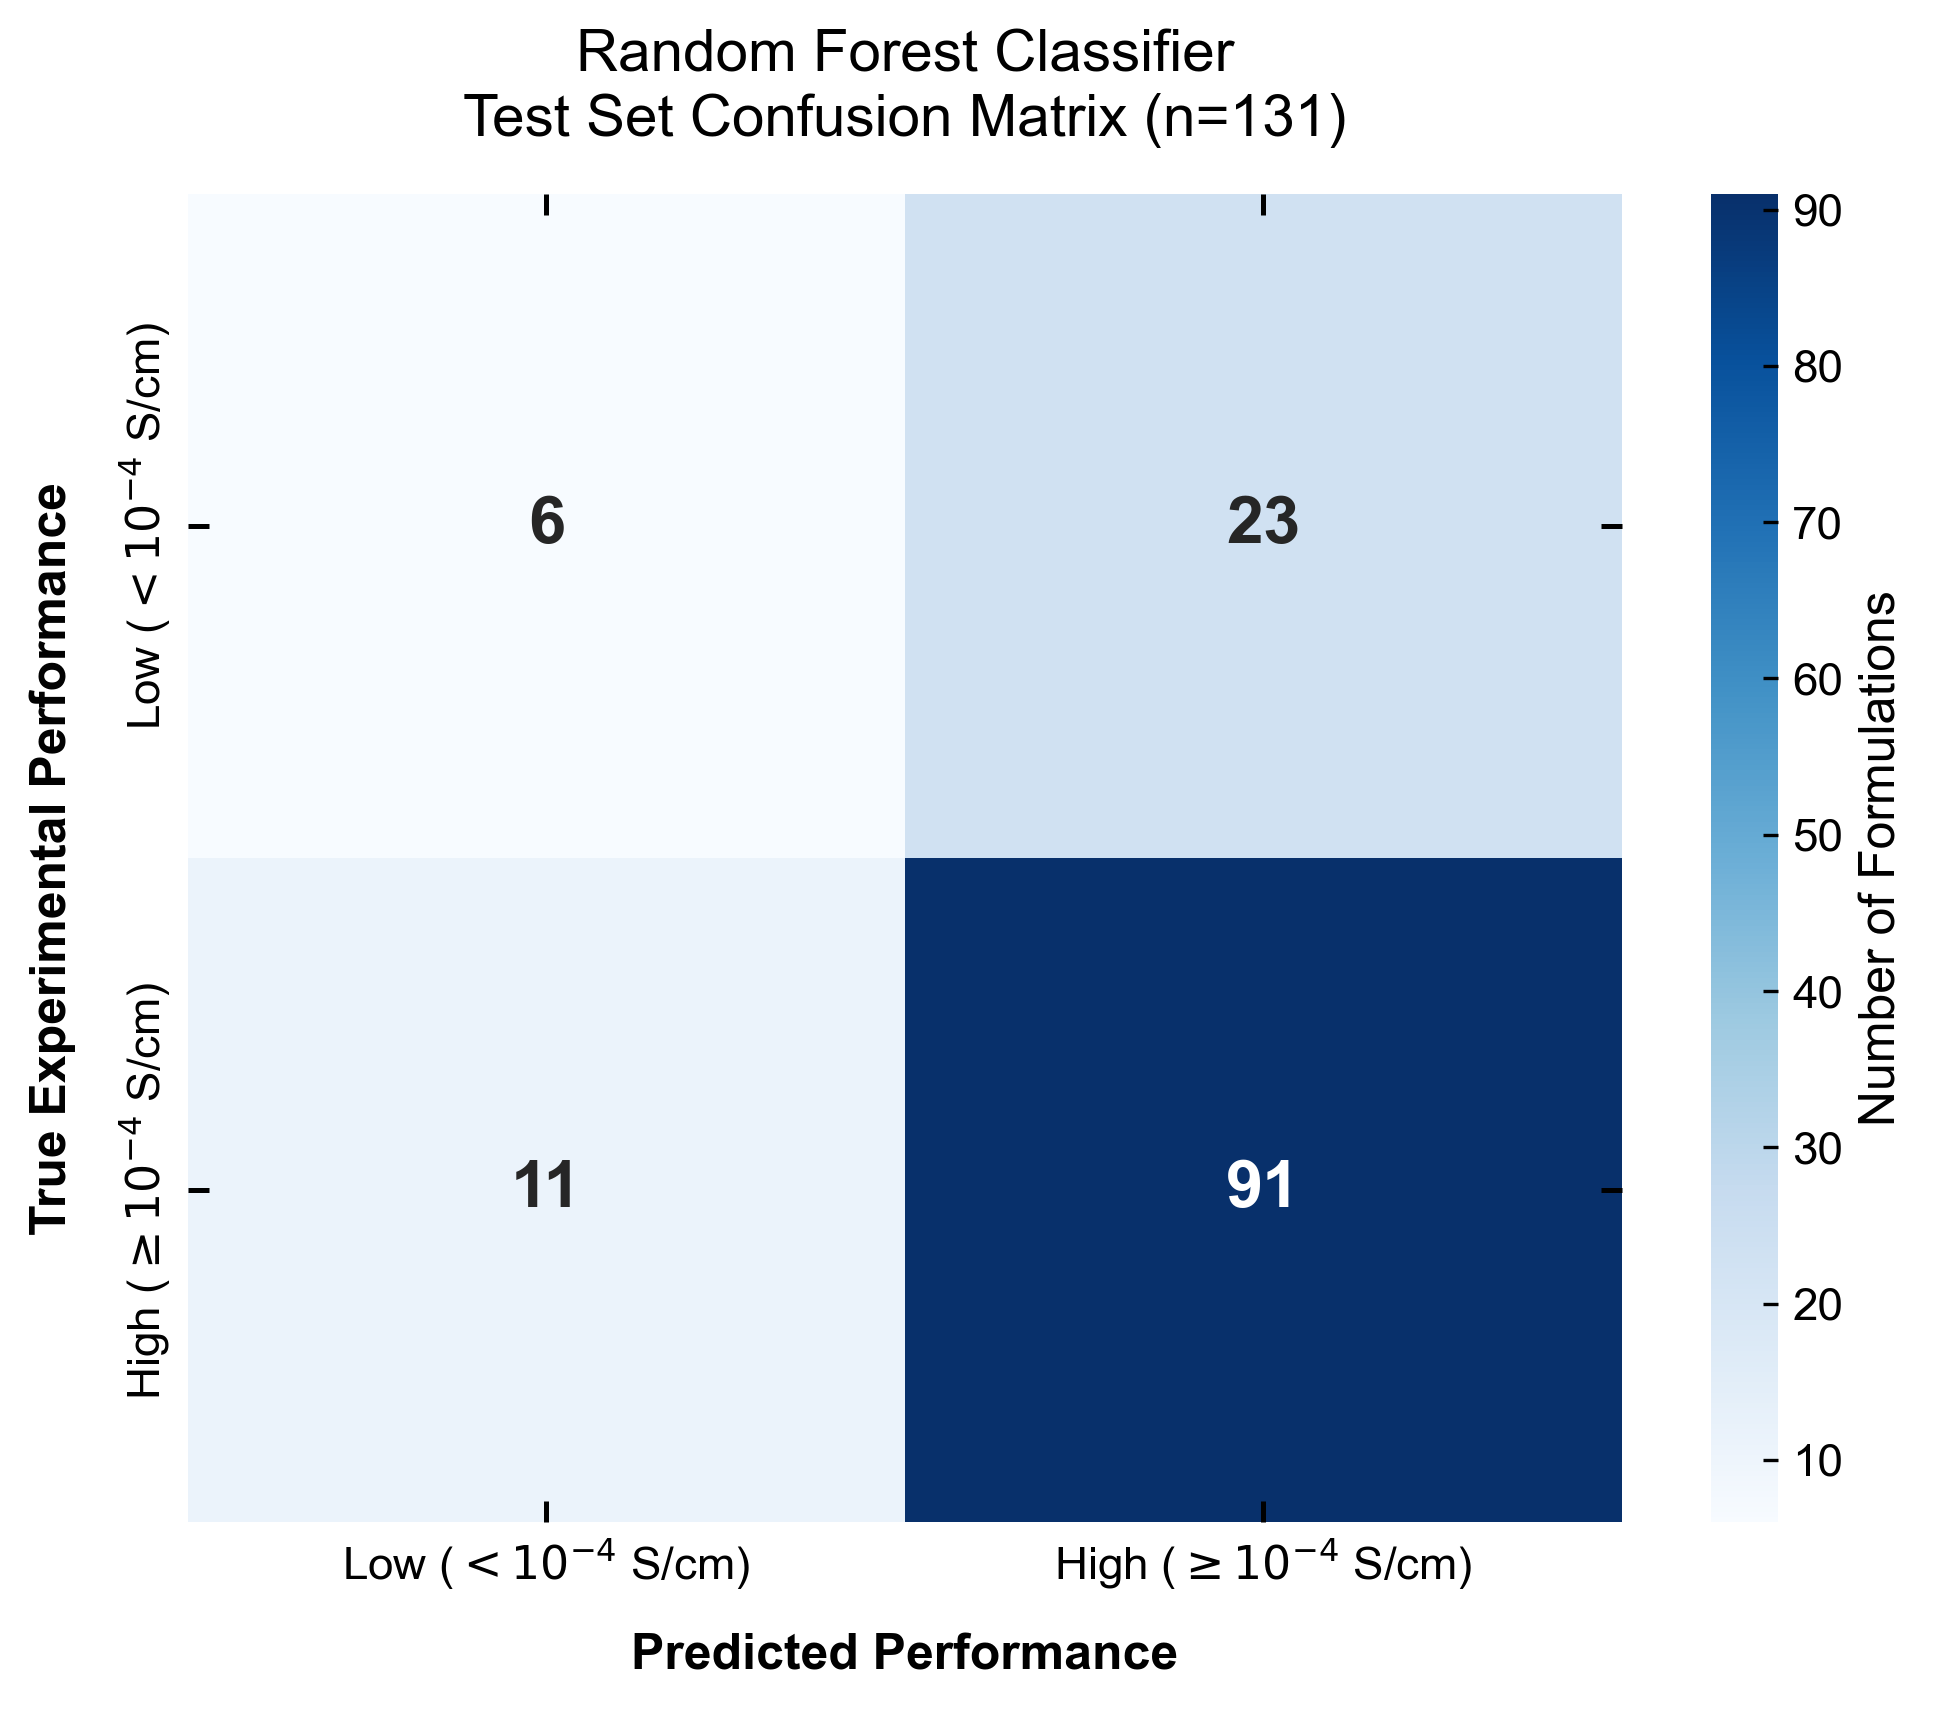

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score


y_pred = rf.predict(X_test)  
y_prob = rf.predict_proba(X_test)[:, 1]

# Compute confusion matrix: [[TN, FP], [FN, TP]]
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Computation of exact metrics for Section S3.4 text
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_val = roc_auc_score(y_test, y_prob)

print(f"=== Holdout Test Set Metrics (n = {len(y_test)}) ===")
print(f"True High-Performance (TP): {tp} (Precision = {precision:.2f}, Recall = {recall:.2f})")
print(f"True Low-Performance  (TN): {tn}")
print(f"False Positives       (FP): {fp}")
print(f"False Negatives       (FN): {fn}")
print(f"Test F1-Score: {f1:.3f} | Test ROC-AUC: {auc_val:.2f}")

# --- Figure S4 matching original SI style ---
fig, ax = plt.subplots(figsize=(6.8, 5.8), dpi=300)

labels = [r'Low ($< 10^{-4}$ S/cm)', r'High ($\geq 10^{-4}$ S/cm)']

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=True,
    xticklabels=labels, yticklabels=labels,
    annot_kws={'size': 16, 'weight': 'bold'},
    cbar_kws={'label': 'Number of Formulations'},
    ax=ax
)

ax.set_title(f'Random Forest Classifier\nTest Set Confusion Matrix (n={len(y_test)})', fontsize=14, pad=14)
ax.set_xlabel('Predicted Performance', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('True Experimental Performance', fontsize=12, fontweight='bold', labelpad=10)

# Style colorbar label and ticks
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11)
cbar.set_label('Number of Formulations', fontsize=12)

ax.tick_params(axis='both', which='major', labelsize=11, length=5, width=1.2)
ax.set_yticklabels(labels, rotation=90, va='center')

plt.tight_layout()
plt.savefig('final_figures/Figure_S4_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# --- Panel 4a ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.scatterplot(data=df, x='poly_fr_ether_mean', y='log10_sigma', 
                hue='has_solv', style='has_fill', palette={True: '#2980b9', False: '#7f8c8d'}, 
                s=70, alpha=0.7, edgecolor='k', ax=ax)
ax.set_xlabel('Mean Ether Fraction')
ax.set_ylabel(L_SIGMA)
ax.legend(title='Has Solvent / Has Filler', fontsize=9, loc='lower right')
format_chem_mater(ax)
plt.savefig('final_figures/4a.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 4b ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.violinplot(data=df, x='Architecture', y='log10_sigma', 
               palette=arch_palette, order=arch_order, inner='box', ax=ax)
ax.set_xlabel('Electrolyte Architecture')
ax.set_ylabel(L_SIGMA)
legend_elements = [Patch(facecolor=arch_palette[arch], edgecolor='k', label=arch) for arch in arch_order]
ax.legend(handles=legend_elements, title='Architecture', loc='lower right', fontsize=10)
format_chem_mater(ax)
plt.savefig('final_figures/4b.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 4c ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
df_mech = df.dropna(subset=['Tensile_Strength_MPa'])
sns.scatterplot(data=df_mech, x='Tensile_Strength_MPa', y='log10_sigma', 
                hue='Architecture', palette=arch_palette, hue_order=arch_order, 
                s=80, alpha=0.8, edgecolor='k', legend=False, ax=ax)
ax.set_xlabel('Tensile Strength [MPa]')
ax.set_ylabel(L_SIGMA)
ax.set_xscale('log')
format_chem_mater(ax)
plt.savefig('final_figures/4c.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 4d ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
heat_cols = ['poly_O_to_C', 'poly_F_to_C', 'poly_fr_nitrile_mean', 'Voltage_Limit_V']
df_heat = df.dropna(subset=heat_cols)
corr = df_heat[heat_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Pearson Correlation'}, ax=ax, 
            annot_kws={'size': 12, 'weight': 'bold'})
ax.set_xticklabels(['O:C', 'F:C', 'Nitrile', 'Voltage'], rotation=45)
ax.set_yticklabels(['O:C', 'F:C', 'Nitrile', 'Voltage'], rotation=0)
format_chem_mater(ax)
plt.savefig('final_figures/4d.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved 4a, 4b, 4c, 4d to final_figures/")

Saved 4a, 4b, 4c, 4d to final_figures/


In [9]:
# --- Panel 5a ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
df_t = df.dropna(subset=['salt_TPSA_mean', 'transference_number'])
sns.scatterplot(data=df_t, x='salt_TPSA_mean', y='transference_number', 
                hue='Architecture', hue_order=arch_order, palette=arch_palette, 
                s=70, alpha=0.7, edgecolor='k', ax=ax)
ax.set_xlabel('Salt TPSA [Å²]')
ax.set_ylabel(r'Lithium Transference Number ($t_+$)')
ax.legend(title='Electrolyte Type', loc='lower right')
format_chem_mater(ax)
plt.savefig('final_figures/5a.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 5b ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
df_ops = df.dropna(subset=['Current_Density_mA_cm2', 'Lifetime_Hours'])
df_ops = df_ops[df_ops['Current_Density_mA_cm2'] > 0 & (df_ops['Lifetime_Hours'] <= 5000)]
scatter = ax.scatter(df_ops['log10_sigma'], df_ops['Current_Density_mA_cm2'], 
                     s=60, c=df_ops['Lifetime_Hours'], cmap='turbo', 
                     norm=LogNorm(vmin=df_ops['Lifetime_Hours'].min(), vmax=df_ops['Lifetime_Hours'].max()),
                     alpha=0.65, edgecolors='k', linewidths=0.5)
ax.set_xlabel(L_SIGMA)
ax.set_ylabel(r'Current Density [$\mathrm{mA \cdot cm^{-2}}$]')
ax.set_yscale('log')
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Symmetric Cell Lifetime [Hours]')
format_chem_mater(ax)
plt.savefig('final_figures/5b.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 5c ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
df_f = df.dropna(subset=['salt_F_to_C', 'Lifetime_Hours'])
# Filter out 
df_f = df_f[(df_f['salt_F_to_C'] < 100) & (df_f['Lifetime_Hours'] <= 5000)]

sns.regplot(data=df_f, x='salt_F_to_C', y='Lifetime_Hours', ax=ax,
            scatter_kws={'alpha':0.6, 'color':'#27ae60', 'edgecolor':'k'}, 
            line_kws={'color':'#2c3e50', 'linewidth':2})

ax.set_xlabel('Salt Fluorine-to-Carbon Ratio')
ax.set_ylabel('Symmetric Cell Lifetime [Hours]')

ax.set_yscale('log')

format_chem_mater(ax)
plt.savefig('final_figures/5c.png', dpi=300, bbox_inches='tight')
plt.close()

# --- Panel 5d ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))
df_front = df.dropna(subset=['transference_number', 'Voltage_Limit_V'])
scatter2 = ax.scatter(df_front['log10_sigma'], df_front['transference_number'], 
                      c=df_front['Voltage_Limit_V'], cmap='plasma', s=70, alpha=0.8, edgecolors='k')
ax.set_xlabel(L_SIGMA)
ax.set_ylabel(r'Lithium Transference Number ($t_+$)')
cbar2 = plt.colorbar(scatter2, ax=ax)
cbar2.set_label('Voltage Limit [V]')
format_chem_mater(ax)
plt.savefig('final_figures/5d.png', dpi=300, bbox_inches='tight')
plt.close()

print("Saved 5a, 5b, 5c, 5d to final_figures/")

Saved 5a, 5b, 5c, 5d to final_figures/


In [10]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

def load_panel(base_dir, panel_name):
    """Automatically loads panel_name whether saved as .png or .jpg."""
    for ext in ['.png', '.jpg', '.jpeg']:
        path = os.path.join(base_dir, f"{panel_name}{ext}")
        if os.path.exists(path):
            return mpimg.imread(path)
    raise FileNotFoundError(f"Could not find {panel_name}.png or .jpg in {base_dir}")

def stitch_2x2(base_dir, prefix, output_name, figsize=(13, 10.5)):
    """Stitches a, b, c, d panels into a publication-ready 2x2 grid."""
    panels = ['a', 'b', 'c', 'd']
    fig, axes = plt.subplots(2, 2, figsize=figsize, dpi=300)
    axes = axes.flatten()
    
    for idx, p in enumerate(panels):
        img = load_panel(base_dir, f"{prefix}{p}")
        axes[idx].imshow(img)
        axes[idx].axis('off')
        # Add bold panel letter (a, b, c, d) in top-left corner
        axes[idx].text(
            -0.02, 1.04, p, transform=axes[idx].transAxes,
            fontsize=18, fontweight='bold', va='top', ha='right'
        )
        
    plt.subplots_adjust(wspace=0.06, hspace=0.08)
    out_path = os.path.join(base_dir, output_name)
    plt.savefig(out_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved 2x2 composite: {out_path}")

def stitch_1x3(base_dir, prefix, output_name, figsize=(16.5, 5.2)):
    """Stitches a, b, c panels into a publication-ready 1x3 horizontal grid."""
    panels = ['a', 'b', 'c']
    fig, axes = plt.subplots(1, 3, figsize=figsize, dpi=300)
    
    for idx, p in enumerate(panels):
        img = load_panel(base_dir, f"{prefix}{p}")
        axes[idx].imshow(img)
        axes[idx].axis('off')
        axes[idx].text(
            -0.02, 1.05, p, transform=axes[idx].transAxes,
            fontsize=18, fontweight='bold', va='top', ha='right'
        )
        
    plt.subplots_adjust(wspace=0.05)
    out_path = os.path.join(base_dir, output_name)
    plt.savefig(out_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved 1x3 composite: {out_path}")

# --- Execute Stitching for All Main-Text Figures ---
folder = 'final_figures'

stitch_2x2(folder, '1', 'Figure_1_Macroscopic_Landscape.png')
stitch_2x2(folder, '2', 'Figure_2_Thermodynamic_Paradox.png')
stitch_1x3(folder, '3', 'Figure_3_ML_Diagnosis.png')
stitch_2x2(folder, '4', 'Figure_4_Multi_Objective.png')
stitch_2x2(folder, '5', 'Figure_5_Cell_Performance.png')

Saved 2x2 composite: final_figures/Figure_1_Macroscopic_Landscape.png
Saved 2x2 composite: final_figures/Figure_2_Thermodynamic_Paradox.png
Saved 1x3 composite: final_figures/Figure_3_ML_Diagnosis.png
Saved 2x2 composite: final_figures/Figure_4_Multi_Objective.png
Saved 2x2 composite: final_figures/Figure_5_Cell_Performance.png


## The Design rules

In [11]:
import os
from math import pi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D

os.makedirs('final_figures', exist_ok=True)


df = pd.read_csv('dataset_final.csv')

In [12]:
# Setup
# ==========================================
conditions = [
    (df['has_solv'] == 0) & (df['has_fill'] == 0),
    (df['has_solv'] > 0)  & (df['has_fill'] == 0),
    (df['has_solv'] == 0) & (df['has_fill'] > 0),
    (df['has_solv'] > 0)  & (df['has_fill'] > 0)
]
choices = ['SPE', 'GPE', 'CPE', 'Hybrid']
df['Architecture'] = np.select(conditions, choices, default='Unknown')

arch_palette = {
    'SPE': '#3498db',     # Blue
    'GPE': '#e74c3c',     # Red
    'CPE': '#2ecc71',     # Green
    'Hybrid': '#9b59b6'   # Purple
}
arch_order = ['SPE', 'CPE', 'GPE', 'Hybrid']

In [13]:
# 1. DATA PREPARATION (6 Axes, 5 Polygons)
# ==========================================
categories = [
    'Conductivity\n($\\log_{10}\\sigma_{RT}$)',
    'Tensile\nStrength',
    'Transference\nNo. ($t_+$)',
    'Voltage\nLimit',
    'Salt F:C\nRatio',
    'Nitrile\nFrac.'
]
radar_cols = [
    'log10_sigma',
    'Tensile_Strength_MPa',
    'transference_number',
    'Voltage_Limit_V',
    'salt_F_to_C',
    'poly_fr_nitrile_mean'
]
N = len(categories)

df_radar_clean = df.dropna(subset=radar_cols + ['Architecture']).copy()
q80_sigma = df_radar_clean['log10_sigma'].quantile(0.80)
q50_tensile = df_radar_clean['Tensile_Strength_MPa'].quantile(0.50)

df_heroes = df_radar_clean[
    (df_radar_clean['log10_sigma'] >= q80_sigma) & 
    (df_radar_clean['Tensile_Strength_MPa'] >= q50_tensile) & 
    (df_radar_clean['transference_number'] >= 0.5)
]


df_heroes[['source.doi', 'Architecture'] + radar_cols].to_csv('final_figures/Table_S_Fig6a_Heroes.csv', index=False)

# Compute group means for each of the 4 classes + Screened 
group_means = {}
for arch in arch_order:
    sub = df_radar_clean[df_radar_clean['Architecture'] == arch]
    group_means[arch] = sub[radar_cols].mean().to_dict()

group_means['Heroes'] = df_heroes[radar_cols].mean().to_dict()

# Physical baseline origins so negative log10_sigma and clustered Voltage_Limit_V scale cleanly
axis_floors = {
    'log10_sigma': -6.0,
    'Tensile_Strength_MPa': 0.0,
    'transference_number': 0.0,
    'Voltage_Limit_V': 3.8,
    'salt_F_to_C': 0.0,
    'poly_fr_nitrile_mean': 0.0
}

norm_polygons = {k: [] for k in group_means.keys()}
for col in radar_cols:
    floor_val = axis_floors.get(col, 0.0)
    raw_vals = {k: max(0.0, group_means[k][col] - floor_val) for k in group_means}
    axis_max = max(raw_vals.values())
    for k in group_means:
        norm_polygons[k].append(raw_vals[k] / axis_max if axis_max > 0 else 0)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]
for k in norm_polygons:
    norm_polygons[k] += norm_polygons[k][:1]

In [14]:
# 2. DATA PREPARATION FOR 6B (Stacked Bar Chart)
# ==========================================
pc_cols = ['Tensile_Strength_MPa', 'transference_number', 'Voltage_Limit_V', 'log10_sigma']
prop_labels = {
    'Tensile_Strength_MPa': 'Tensile Strength (MPa)',
    'transference_number': 'Transference No. ($t_+$)',
    'Voltage_Limit_V': 'Voltage Limit (V)',
    'log10_sigma': 'Conductivity ($\\log_{10}\\sigma_{RT}$)'
}

prop_colors = {
    'Tensile_Strength_MPa': '#1D3557',  # Deep Navy Slate
    'transference_number':  '#2A9D8F',  # Teal Cyan
    'Voltage_Limit_V':      '#E9C46A',  # Warm Sand Gold
    'log10_sigma':          '#F4A261'   # Coral Amber
}

df_pc = df.dropna(subset=pc_cols + ['Architecture']).copy()
df_pc_raw_medians = df_pc.groupby('Architecture')[pc_cols].median().reindex(arch_order).reset_index()
df_pc_raw_medians.to_csv('final_figures/Table_S_Fig6b_Raw_Medians.csv', index=False)

# Standardize each property across the 4 class medians onto [0.20, 1.00] (Max Composite Index = 4.00)
df_b_norm = df_pc_raw_medians.copy()
for col in pc_cols:
    c_min = df_pc_raw_medians[col].min()
    c_max = df_pc_raw_medians[col].max()
    if c_max > c_min:
        df_b_norm[col] = 0.20 + 0.80 * (df_pc_raw_medians[col] - c_min) / (c_max - c_min)
    else:
        df_b_norm[col] = 1.0

In [15]:
# 3. HELPER PLOTTING FUNCTIONS FOR 6A, 6B, 6C
# ==========================================
def plot_panel_6a(ax_radar):
    ax_radar.set_theta_offset(pi / 2)
    ax_radar.set_theta_direction(-1)
    plt.sca(ax_radar)
    plt.xticks(angles[:-1], categories, size=10.5, fontweight='bold')
    ax_radar.tick_params(axis='x', pad=16)
    ax_radar.set_rlabel_position(30)
    plt.yticks([0.25, 0.5, 0.75, 1.0], ["25%", "50%", "75%", "Max"], color="#555555", size=8.5)
    plt.ylim(0, 1.08)

    for arch in arch_order:
        ax_radar.plot(angles, norm_polygons[arch], linewidth=2.2, linestyle='solid',
                      marker='o', markersize=5, label=f'{arch} Average', color=arch_palette[arch], alpha=0.9)
        ax_radar.fill(angles, norm_polygons[arch], color=arch_palette[arch], alpha=0.07)

    # Neon Gold / Electric Amber highlight for Jointly Screened Heroes
    hero_neon = '#FFB703'
    hero_edge = '#FB8500'
    ax_radar.plot(angles, norm_polygons['Heroes'], linewidth=3.2, linestyle='--',
                  marker='D', markersize=7, label='Co-optimized Cohort', color=hero_edge,
                  markerfacecolor=hero_neon, markeredgecolor='k', zorder=10)
    ax_radar.fill(angles, norm_polygons['Heroes'], color=hero_neon, alpha=0.25, zorder=8)
    ax_radar.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False, fontsize=9.5)

def plot_panel_6b(ax_bar):
    x_pos = np.arange(len(arch_order))
    bottoms = np.zeros(len(arch_order))

    for col in pc_cols:
        heights = df_b_norm[col].values
        raw_vals = df_pc_raw_medians[col].values
        ax_bar.bar(x_pos, heights, bottom=bottoms, width=0.64,
                   color=prop_colors[col], edgecolor='white', linewidth=1.5,
                   label=prop_labels[col], alpha=0.95)
        
        for i, (h, r_val) in enumerate(zip(heights, raw_vals)):
            if col == 'Tensile_Strength_MPa':
                txt = f"{r_val:.2f} MPa"
            elif col == 'transference_number':
                txt = f"{r_val:.2f}"
            elif col == 'Voltage_Limit_V':
                txt = f"{r_val:.2f} V"
            else:
                txt = f"{r_val:.2f}"
            
            txt_color = 'white' if col in ['Tensile_Strength_MPa', 'transference_number'] else '#1a1a1a'
            ax_bar.text(x_pos[i], bottoms[i] + h/2.0, txt, ha='center', va='center',
                        fontsize=8.2, fontweight='bold', color=txt_color)
        bottoms += heights

    for i, total in enumerate(bottoms):
        ax_bar.text(x_pos[i], total + 0.07, f"Score: {total:.2f}", ha='center', va='bottom',
                    fontsize=9.5, fontweight='bold', color='#1D3557')

    ax_bar.set_xticks(x_pos)
    ax_bar.set_xticklabels(arch_order, fontweight='bold', fontsize=11)
    ax_bar.set_ylabel('Composite Multi-Objective Index (Max = 4.0)', fontsize=11, fontweight='bold')
    ax_bar.set_ylim(0, 4.18)
    ax_bar.legend(loc='upper left', frameon=False, fontsize=9.5)
    format_chem_mater(ax_bar)

# def plot_panel_6c(ax_rule):
#     ax_rule.set_xlim(0, 10)
#     ax_rule.set_ylim(0, 10)
#     ax_rule.axis('off')

#     # Header Banner
#     ax_rule.add_patch(FancyBboxPatch((0.15, 9.10), 9.7, 0.72, boxstyle="round,pad=0.08,rounding_size=0.15",
#                                      facecolor='#1D3557', edgecolor='none'))
#     ax_rule.text(5.0, 9.46, "QUANTITATIVE MULTI-PHASE DESIGN BLUEPRINT", ha='center', va='center',
#                  color='white', fontsize=10.8, fontweight='bold')

#     # --- CARD I: Stoichiometry & Chain Dynamics ---
#     ax_rule.add_patch(FancyBboxPatch((0.15, 6.65), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
#     ax_rule.add_patch(FancyBboxPatch((0.15, 6.65), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#2980B9', edgecolor='none'))
#     ax_rule.text(0.82, 7.68, "RULE\nI", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
#     ax_rule.text(1.75, 8.35, "1. Host Stoichiometry & Segmental Mobility", ha='left', va='center',
#                  color='#0F172A', fontsize=9.8, fontweight='bold')
#     ax_rule.text(1.75, 7.95, "Balance Li+ solvation against 5-EO chelation trapping (T_test - T_g > 50 °C)",
#                  ha='left', va='center', color='#475569', fontsize=8.0)

#     ax_rule.add_patch(FancyBboxPatch((1.75, 6.90), 2.35, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#FADBD8', edgecolor='#E74C3C', linewidth=1.2))
#     ax_rule.text(2.92, 7.26, "O:Li < 12\nOverbinding Trap", ha='center', va='center', color='#922B21', fontsize=7.5, fontweight='bold')

#     ax_rule.add_patch(FancyBboxPatch((4.25, 6.90), 2.95, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#D4EFDF', edgecolor='#27AE60', linewidth=1.8))
#     ax_rule.text(5.72, 7.26, "O:Li = 15–20 (TARGET)\nPeak Hopping (σ > 10⁻⁴)", ha='center', va='center', color='#145A32', fontsize=7.6, fontweight='bold')

#     ax_rule.add_patch(FancyBboxPatch((7.35, 6.90), 2.25, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#E2E8F0', edgecolor='#64748B', linewidth=1.2))
#     ax_rule.text(8.47, 7.26, "O:Li > 25\nCarrier Dilution", ha='center', va='center', color='#334155', fontsize=7.5, fontweight='bold')

#     # --- CARD II: Orthogonal Phase Decoupling ---
#     ax_rule.add_patch(FancyBboxPatch((0.15, 4.20), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
#     ax_rule.add_patch(FancyBboxPatch((0.15, 4.20), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#8E44AD', edgecolor='none'))
#     ax_rule.text(0.82, 5.22, "RULE\nII", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
#     ax_rule.text(1.75, 5.90, "2. Orthogonal Mechanical–Ionic Phase Decoupling", ha='left', va='center',
#                  color='#0F172A', fontsize=9.8, fontweight='bold')
#     ax_rule.text(1.75, 5.50, "Bypass the single-phase SPE strength–conductivity trade-off",
#                  ha='left', va='center', color='#475569', fontsize=8.0)

#     ax_rule.add_patch(FancyBboxPatch((1.75, 4.45), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#EDE9FE', edgecolor='#7C3AED', linewidth=1.4))
#     ax_rule.text(3.60, 4.81, "3D Ceramic / Fiber Skeleton\nTarget: Tensile ≥ 5.0 MPa", ha='center', va='center', color='#4C1D95', fontsize=7.5, fontweight='bold')

#     ax_rule.text(5.68, 4.81, "⊕", ha='center', va='center', color='#6D28D9', fontsize=13, fontweight='bold')

#     ax_rule.add_patch(FancyBboxPatch((5.90, 4.45), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#FCE7F3', edgecolor='#DB2777', linewidth=1.4))
#     ax_rule.text(7.75, 4.81, "Percolating Interfacial Phase\nTarget: σ_RT ≥ 10⁻³·⁵ S cm⁻¹", ha='center', va='center', color='#831843', fontsize=7.5, fontweight='bold')

#     # --- CARD III: Anion Trapping & High-Voltage SEI ---
#     ax_rule.add_patch(FancyBboxPatch((0.15, 1.75), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
#     ax_rule.add_patch(FancyBboxPatch((0.15, 1.75), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#16A085', edgecolor='none'))
#     ax_rule.text(0.82, 2.78, "RULE\nIII", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
#     ax_rule.text(1.75, 3.45, "3. Anion Immobilization & Cathodic Passivation", ha='left', va='center',
#                  color='#0F172A', fontsize=9.8, fontweight='bold')
#     ax_rule.text(1.75, 3.05, "Suppress space-charge polarization and oxidative degradation at high voltage",
#                  ha='left', va='center', color='#475569', fontsize=8.0)

#     ax_rule.add_patch(FancyBboxPatch((1.75, 2.00), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#CCFBF1', edgecolor='#0D9488', linewidth=1.4))
#     ax_rule.text(3.60, 2.36, "Steric / Lewis-Acid Anion Trap\nSalt TPSA ≥ 85 Å² → t_Li+ ≥ 0.50", ha='center', va='center', color='#115E59', fontsize=7.4, fontweight='bold')

#     ax_rule.text(5.68, 2.36, "⊕", ha='center', va='center', color='#0F766E', fontsize=13, fontweight='bold')

#     ax_rule.add_patch(FancyBboxPatch((5.90, 2.00), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
#                                      facecolor='#E0F2FE', edgecolor='#0284C7', linewidth=1.4))
#     ax_rule.text(7.75, 2.36, "Fluorinated + Nitrile Motifs\nSalt F:C ≥ 3.0 → Window ≥ 4.8 V", ha='center', va='center', color='#075985', fontsize=7.4, fontweight='bold')

#     # Downward flow arrows between cards
#     for y_top, y_bot in [(6.65, 6.25), (4.20, 3.80), (1.75, 1.35)]:
#         ax_rule.annotate('', xy=(5.0, y_bot), xytext=(5.0, y_top),
#                          arrowprops=dict(arrowstyle="->,head_width=0.3,head_length=0.2", color='#334155', lw=2.0))

#     # --- BOTTOM CONVERGENCE BANNER ---
#     ax_rule.add_patch(FancyBboxPatch((0.15, 0.12), 9.7, 1.20, boxstyle="round,pad=0.06,rounding_size=0.16",
#                                      facecolor='#FFFBEB', edgecolor='#F59E0B', linewidth=2.0))
#     ax_rule.text(5.0, 1.04, "JOINTLY SCREENED MULTI-PHASE TARGET PERFORMANCE ENVELOPE", ha='center', va='center',
#                  color='#B45309', fontsize=9.2, fontweight='bold')

#     pills = [
#         (1.42, "σ_RT ≥ 10⁻⁴ S/cm"),
#         (3.80, "Tensile ≥ 5 MPa"),
#         (6.20, "t_Li+ ≥ 0.50"),
#         (8.58, "Stability ≥ 4.8 V")
#     ]
#     for px, p_txt in pills:
#         ax_rule.add_patch(FancyBboxPatch((px - 1.05, 0.25), 2.1, 0.48, boxstyle="round,pad=0.04,rounding_size=0.12",
#                                          facecolor='#FEF3C7', edgecolor='#D97706', linewidth=1.2))
#         ax_rule.text(px, 0.49, p_txt, ha='center', va='center', color='#92400E', fontsize=7.8, fontweight='bold')





plt.rcParams['mathtext.default'] = 'regular'

def plot_panel_6c(ax_rule):
    ax_rule.set_xlim(0, 10)
    ax_rule.set_ylim(0, 10)
    ax_rule.axis('off')

    # Header Banner
    ax_rule.add_patch(FancyBboxPatch((0.15, 9.10), 9.7, 0.72, boxstyle="round,pad=0.08,rounding_size=0.15",
                                     facecolor='#1D3557', edgecolor='none'))
    ax_rule.text(5.0, 9.46, "QUANTITATIVE MULTI-PHASE DESIGN BLUEPRINT", ha='center', va='center',
                 color='white', fontsize=10.8, fontweight='bold')

    # --- CARD I: Stoichiometry & Chain Dynamics ---
    ax_rule.add_patch(FancyBboxPatch((0.15, 6.65), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
    ax_rule.add_patch(FancyBboxPatch((0.15, 6.65), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#2980B9', edgecolor='none'))
    ax_rule.text(0.82, 7.68, "RULE\nI", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax_rule.text(1.75, 8.35, "1. Host Stoichiometry & Segmental Mobility", ha='left', va='center',
                 color='#0F172A', fontsize=9.8, fontweight='bold')
    ax_rule.text(1.75, 7.95, r"Balance $\mathrm{Li^+}$ solvation against 5-EO chelation trapping ($T_{\mathrm{test}} - T_g > 50\ ^\circ\mathrm{C}$)",
                 ha='left', va='center', color='#475569', fontsize=8.0)

    ax_rule.add_patch(FancyBboxPatch((1.75, 6.90), 2.35, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#FADBD8', edgecolor='#E74C3C', linewidth=1.2))
    ax_rule.text(2.92, 7.26, "O:Li < 12\nOverbinding Trap", ha='center', va='center', color='#922B21', fontsize=7.5, fontweight='bold')

    ax_rule.add_patch(FancyBboxPatch((4.25, 6.90), 2.95, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#D4EFDF', edgecolor='#27AE60', linewidth=1.8))
    ax_rule.text(5.72, 7.26, "O:Li = 15-20 (TARGET)\n" + r"Peak Hopping ($\sigma_{RT} > 10^{-4}$)",
                 ha='center', va='center', color='#145A32', fontsize=7.6, fontweight='bold')

    ax_rule.add_patch(FancyBboxPatch((7.35, 6.90), 2.25, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#E2E8F0', edgecolor='#64748B', linewidth=1.2))
    ax_rule.text(8.47, 7.26, "O:Li > 25\nCarrier Dilution", ha='center', va='center', color='#334155', fontsize=7.5, fontweight='bold')

    # --- CARD II: Orthogonal Phase Decoupling ---
    ax_rule.add_patch(FancyBboxPatch((0.15, 4.20), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
    ax_rule.add_patch(FancyBboxPatch((0.15, 4.20), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#8E44AD', edgecolor='none'))
    ax_rule.text(0.82, 5.22, "RULE\nII", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax_rule.text(1.75, 5.90, "2. Orthogonal Mechanical-Ionic Phase Decoupling", ha='left', va='center',
                 color='#0F172A', fontsize=9.8, fontweight='bold')
    ax_rule.text(1.75, 5.50, "Bypass the single-phase SPE strength-conductivity trade-off",
                 ha='left', va='center', color='#475569', fontsize=8.0)

    ax_rule.add_patch(FancyBboxPatch((1.75, 4.45), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#EDE9FE', edgecolor='#7C3AED', linewidth=1.4))
    ax_rule.text(3.60, 4.81, "3D Ceramic / Fiber Skeleton\n" + r"Target: Tensile $\geq 5.0\ \mathrm{MPa}$",
                 ha='center', va='center', color='#4C1D95', fontsize=7.5, fontweight='bold')

    ax_rule.text(5.68, 4.81, "+", ha='center', va='center', color='#6D28D9', fontsize=14, fontweight='bold')

    ax_rule.add_patch(FancyBboxPatch((5.90, 4.45), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#FCE7F3', edgecolor='#DB2777', linewidth=1.4))
    ax_rule.text(7.75, 4.81, "Percolating Interfacial Phase\n" + r"Target: $\sigma_{RT} \geq 10^{-3.5}\ \mathrm{S\ cm^{-1}}$",
                 ha='center', va='center', color='#831843', fontsize=7.5, fontweight='bold')

    # --- CARD III: Anion Trapping & High-Voltage SEI ---
    ax_rule.add_patch(FancyBboxPatch((0.15, 1.75), 9.7, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#F8FAFC', edgecolor='#CBD5E1', linewidth=1.5))
    ax_rule.add_patch(FancyBboxPatch((0.15, 1.75), 1.35, 2.05, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#16A085', edgecolor='none'))
    ax_rule.text(0.82, 2.78, "RULE\nIII", ha='center', va='center', color='white', fontsize=11, fontweight='bold')
    ax_rule.text(1.75, 3.45, "3. Anion Immobilization & Cathodic Passivation", ha='left', va='center',
                 color='#0F172A', fontsize=9.8, fontweight='bold')
    ax_rule.text(1.75, 3.05, "Suppress space-charge polarization and oxidative degradation at high voltage",
                 ha='left', va='center', color='#475569', fontsize=8.0)

    ax_rule.add_patch(FancyBboxPatch((1.75, 2.00), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#CCFBF1', edgecolor='#0D9488', linewidth=1.4))
    ax_rule.text(3.60, 2.36, "Steric / Lewis-Acid Anion Trap\n" + r"Salt TPSA $\geq 85\ \mathrm{\AA^2} \rightarrow t_{\mathrm{Li^+}} \geq 0.50$",
                 ha='center', va='center', color='#115E59', fontsize=7.4, fontweight='bold')

    ax_rule.text(5.68, 2.36, "+", ha='center', va='center', color='#0F766E', fontsize=14, fontweight='bold')

    ax_rule.add_patch(FancyBboxPatch((5.90, 2.00), 3.70, 0.72, boxstyle="round,pad=0.02,rounding_size=0.08",
                                     facecolor='#E0F2FE', edgecolor='#0284C7', linewidth=1.4))
    ax_rule.text(7.75, 2.36, "Fluorinated + Nitrile Motifs\n" + r"Salt F:C $\geq 3.0 \rightarrow$ Window $\geq 4.8\ \mathrm{V}$",
                 ha='center', va='center', color='#075985', fontsize=7.4, fontweight='bold')

    # Downward flow arrows between cards
    for y_top, y_bot in [(6.65, 6.25), (4.20, 3.80), (1.75, 1.35)]:
        ax_rule.annotate('', xy=(5.0, y_bot), xytext=(5.0, y_top),
                         arrowprops=dict(arrowstyle="->,head_width=0.3,head_length=0.2", color='#334155', lw=2.0))

    # --- BOTTOM CONVERGENCE BANNER ---
    ax_rule.add_patch(FancyBboxPatch((0.15, 0.12), 9.7, 1.20, boxstyle="round,pad=0.06,rounding_size=0.16",
                                     facecolor='#FFFBEB', edgecolor='#F59E0B', linewidth=2.0))
    ax_rule.text(5.0, 1.04, "JOINTLY SCREENED MULTI-PHASE TARGET PERFORMANCE ENVELOPE", ha='center', va='center',
                 color='#B45309', fontsize=9.2, fontweight='bold')

    pills = [
        (1.42, r"$\sigma_{RT} \geq 10^{-4}\ \mathrm{S/cm}$"),
        (3.80, r"Tensile $\geq 5\ \mathrm{MPa}$"),
        (6.20, r"$t_{\mathrm{Li^+}} \geq 0.50$"),
        (8.58, r"Stability $\geq 4.8\ \mathrm{V}$")
    ]
    for px, p_txt in pills:
        ax_rule.add_patch(FancyBboxPatch((px - 1.05, 0.25), 2.1, 0.48, boxstyle="round,pad=0.04,rounding_size=0.12",
                                         facecolor='#FEF3C7', edgecolor='#D97706', linewidth=1.2))
        ax_rule.text(px, 0.49, p_txt, ha='center', va='center', color='#92400E', fontsize=7.8, fontweight='bold')


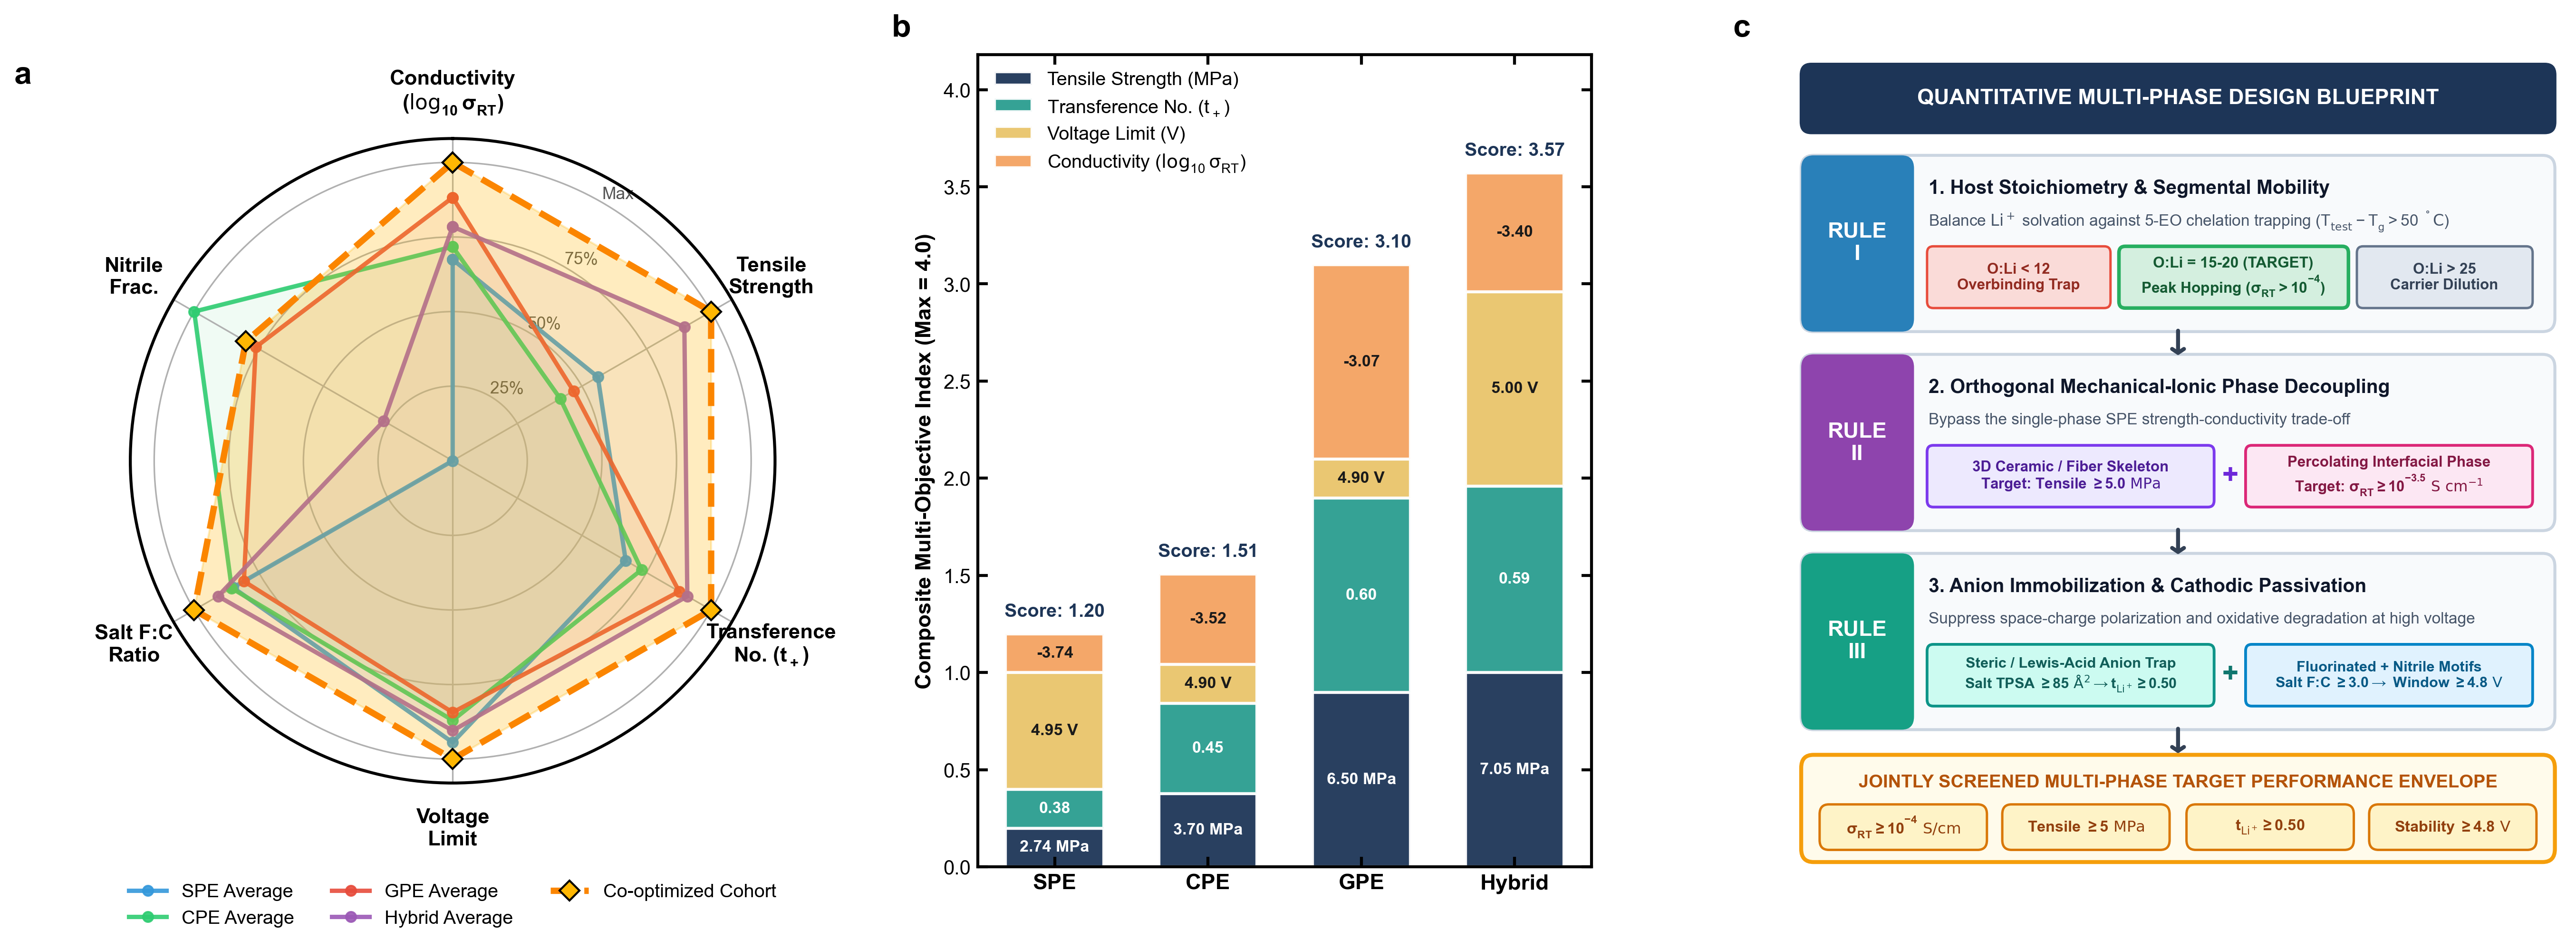

In [16]:
# 4. SAVE INDIVIDUAL PANELS & COMBINED FIGURE
# ==========================================
# Save 6a.png
fig_a = plt.figure(figsize=(7.5, 7.2))
ax_a = fig_a.add_subplot(111, polar=True)
plot_panel_6a(ax_a)
plt.savefig('final_figures/6a.png', dpi=300, bbox_inches='tight')
plt.close(fig_a)

# Save 6b.png
fig_b, ax_b = plt.subplots(figsize=(7.2, 6.8))
plot_panel_6b(ax_b)
plt.savefig('final_figures/6b.png', dpi=300, bbox_inches='tight')
plt.close(fig_b)

# Save 6c.png
fig_c, ax_c = plt.subplots(figsize=(8.8, 6.8))
plot_panel_6c(ax_c)
plt.savefig('final_figures/6c.png', dpi=300, bbox_inches='tight')
plt.close(fig_c)

# Save Combined 3-Panel Figure 6
fig_all = plt.figure(figsize=(22, 7.4))
gs = fig_all.add_gridspec(1, 3, width_ratios=[1.05, 1.0, 1.25], wspace=0.30)

ax1 = fig_all.add_subplot(gs[0], polar=True)
plot_panel_6a(ax1)
ax1.text(-0.18, 1.12, 'a', transform=ax1.transAxes, fontsize=16, fontweight='bold', va='top')

ax2 = fig_all.add_subplot(gs[1])
plot_panel_6b(ax2)
ax2.text(-0.14, 1.05, 'b', transform=ax2.transAxes, fontsize=16, fontweight='bold', va='top')

ax3 = fig_all.add_subplot(gs[2])
plot_panel_6c(ax3)
ax3.text(-0.08, 1.05, 'c', transform=ax3.transAxes, fontsize=16, fontweight='bold', va='top')

plt.savefig('final_figures/Figure_6_Design_Blueprint.png', dpi=300, bbox_inches='tight')
plt.show()